# 11 - Formation & Interval Analysis

[![Open in Colab](https://colab.research.google.com/assets/colab-badge.svg)](https://colab.research.google.com/github/sambalshikhar/petrophys/blob/main/examples/part_b_advanced/11_formation_and_interval_analysis.ipynb)

**Part B - Petrophys Curriculum**

A curve-by-curve interpretation answers *"what is the rock doing at this
depth?"*. A **formation analysis** answers the question the asset team actually
asks: *"how much net pay does each formation carry, and what are its average
properties?"*

This lesson takes the curves produced by the dynamic workflow (Lesson 10)
and rolls them up by geological interval. We will:

1. Load **formation tops** (`formations_30_6-5`) and per-interval
   **lithology** (`lithology_30_6-5`), both bundled with the package.
2. Attach both to the well and plot them against the logs.
3. Interpret the well and produce the **per-formation report** with
   `result.formation_summary(rank="formation")` - and see why flags in the
   shallow overburden must not be counted as pay.
4. Summarise any depth window with `result.zone_summary` and
   `result.summary(top=..., bottom=...)`.
5. See what top-only picks and nested groups do to a table, and go from a
   file to the report in one line.
6. Draw a **depth plot with formation shading**.

We use well **30/6-5**, whose reservoir is the Brent Group (Ness and Etive
formations, 2841-2958 m).

In [1]:
# In Google Colab, this cell installs Petrophys (about a minute).
# Anywhere else it does nothing.
import sys

if "google.colab" in sys.modules:
    %pip install --quiet "petrophys[ml]"

## Learning goals

- Load formation tops with `pp.read_formations` and read their rank (group or
  formation) and parent columns.
- Attach tops and per-interval lithology to a well and plot them.
- Report net pay, NTG and average properties per formation with
  `result.formation_summary(rank=...)`, and explain why shallow, poorly
  compacted intervals can pass net-pay cutoffs.
- Summarise any depth windows with `result.zone_summary(zones)` and a window
  with `result.summary(top=..., bottom=...)`.
- Know what top-only picks and nested groups do to a table's totals.
- Run the file-to-report route in one line, and shade the reservoir intervals
  on a depth plot.

### Prerequisites

Lesson 10 (the dynamic workflow) - we reuse the same interpretation settings here.

## Why this matters

Formation tops turn a continuous log into *accountable units*. NTG and net pay
per formation feed directly into volumetrics and reserves. Getting the interval
geometry right (correct depth reference, no accidental overlaps, clipped to the
logged interval) is half the job; the arithmetic is one call on the
interpretation result.

In [2]:
import warnings
import pandas as pd
import petrophys as pp
from petrophys.visualization import add_zone_shading

pd.set_option("display.precision", 3)
pd.set_option("display.max_columns", 30)

## 1. Load formations through the shared importer

Formations are optional for plotting and interpretation; they are needed only
when you want geological annotations or interval roll-ups. `pp.read_formations`
is the reader the well, the plots and the formation summaries share. It keeps
every row, and it reads the rank from NPD-style names (`Gp.` = group, `Fm.` =
formation); the bundled 30/6-5 table also gives each formation its parent group.
For external files, see [Your own data](../../docs/own_data.md).

In [3]:
tops = pp.read_formations(pp.sample("formations_30_6-5"))
tops

,formation_name,top_depth,bottom_depth,lithology,rank,parent,depth_unit
0,NORDLAND GP.,181.0,726.0,Shale,group,,m
1,Utsira Fm.,726.0,879.0,Sandstone,formation,,m
2,HORDALAND GP.,879.0,1908.0,Shale,group,,m
3,ROGALAND GP.,1908.0,2203.0,Shale,group,,m
4,Balder Fm.,1908.0,2023.0,Shale,formation,ROGALAND GP.,m
5,Sele Fm.,2023.0,2123.0,Shale,formation,ROGALAND GP.,m
6,Lista Fm.,2123.0,2203.0,Shale,formation,ROGALAND GP.,m
7,SHETLAND GP.,2203.0,2408.0,Marl,group,,m
8,CROMER KNOLL GP.,2408.0,2452.0,Marl,group,,m
9,VIKING GP.,2452.0,2841.0,Shale,group,,m


The groups and the formations within them overlap: `BRENT GP.` (2841-2958 m)
is the Ness plus the Etive Formation. Some groups have no formation rows at all
(Nordland, Hordaland, Shetland, Cromer Knoll), and the Statfjord Formation has
no group row. A nested table is ordinary pandas to query - for example the
formations of the Brent Group:

In [4]:
tops[tops["parent"] == "BRENT GP."]

,formation_name,top_depth,bottom_depth,lithology,rank,parent,depth_unit
13,Ness Fm.,2841.0,2865.0,Sandstone,formation,BRENT GP.,m
14,Etive Fm.,2865.0,2958.0,Sandstone,formation,BRENT GP.,m


## 2. Attach tops and a second layer of intervals

`pp.read(..., formations=...)` attaches the tops to the well; plots annotate
them, and `pp.interpret` offers them to the workflow for formation-specific core
calibration. The second bundled table, `lithology_30_6-5.csv`, is a coarser
`top, bottom, lithology` column with no formation names - a simplified
lithology per interval. `pp.plot(..., lithology=...)` draws it in place of the
well's embedded lithology log, so you can check the two layers against the
logs:

[repository]\src\petrophys\preprocessing\standardization\curve_standardizer.py:851: UserWarning: SWC: inferred percent core saturation despite unit 'frac'; divided by 100 to v/v. Verify source units.
  standardize_core_saturation(new_curve, inplace=True)
[repository]\src\petrophys\preprocessing\standardization\curve_standardizer.py:851: UserWarning: SOC: inferred percent core saturation despite unit 'frac'; divided by 100 to v/v. Verify source units.
  standardize_core_saturation(new_curve, inplace=True)


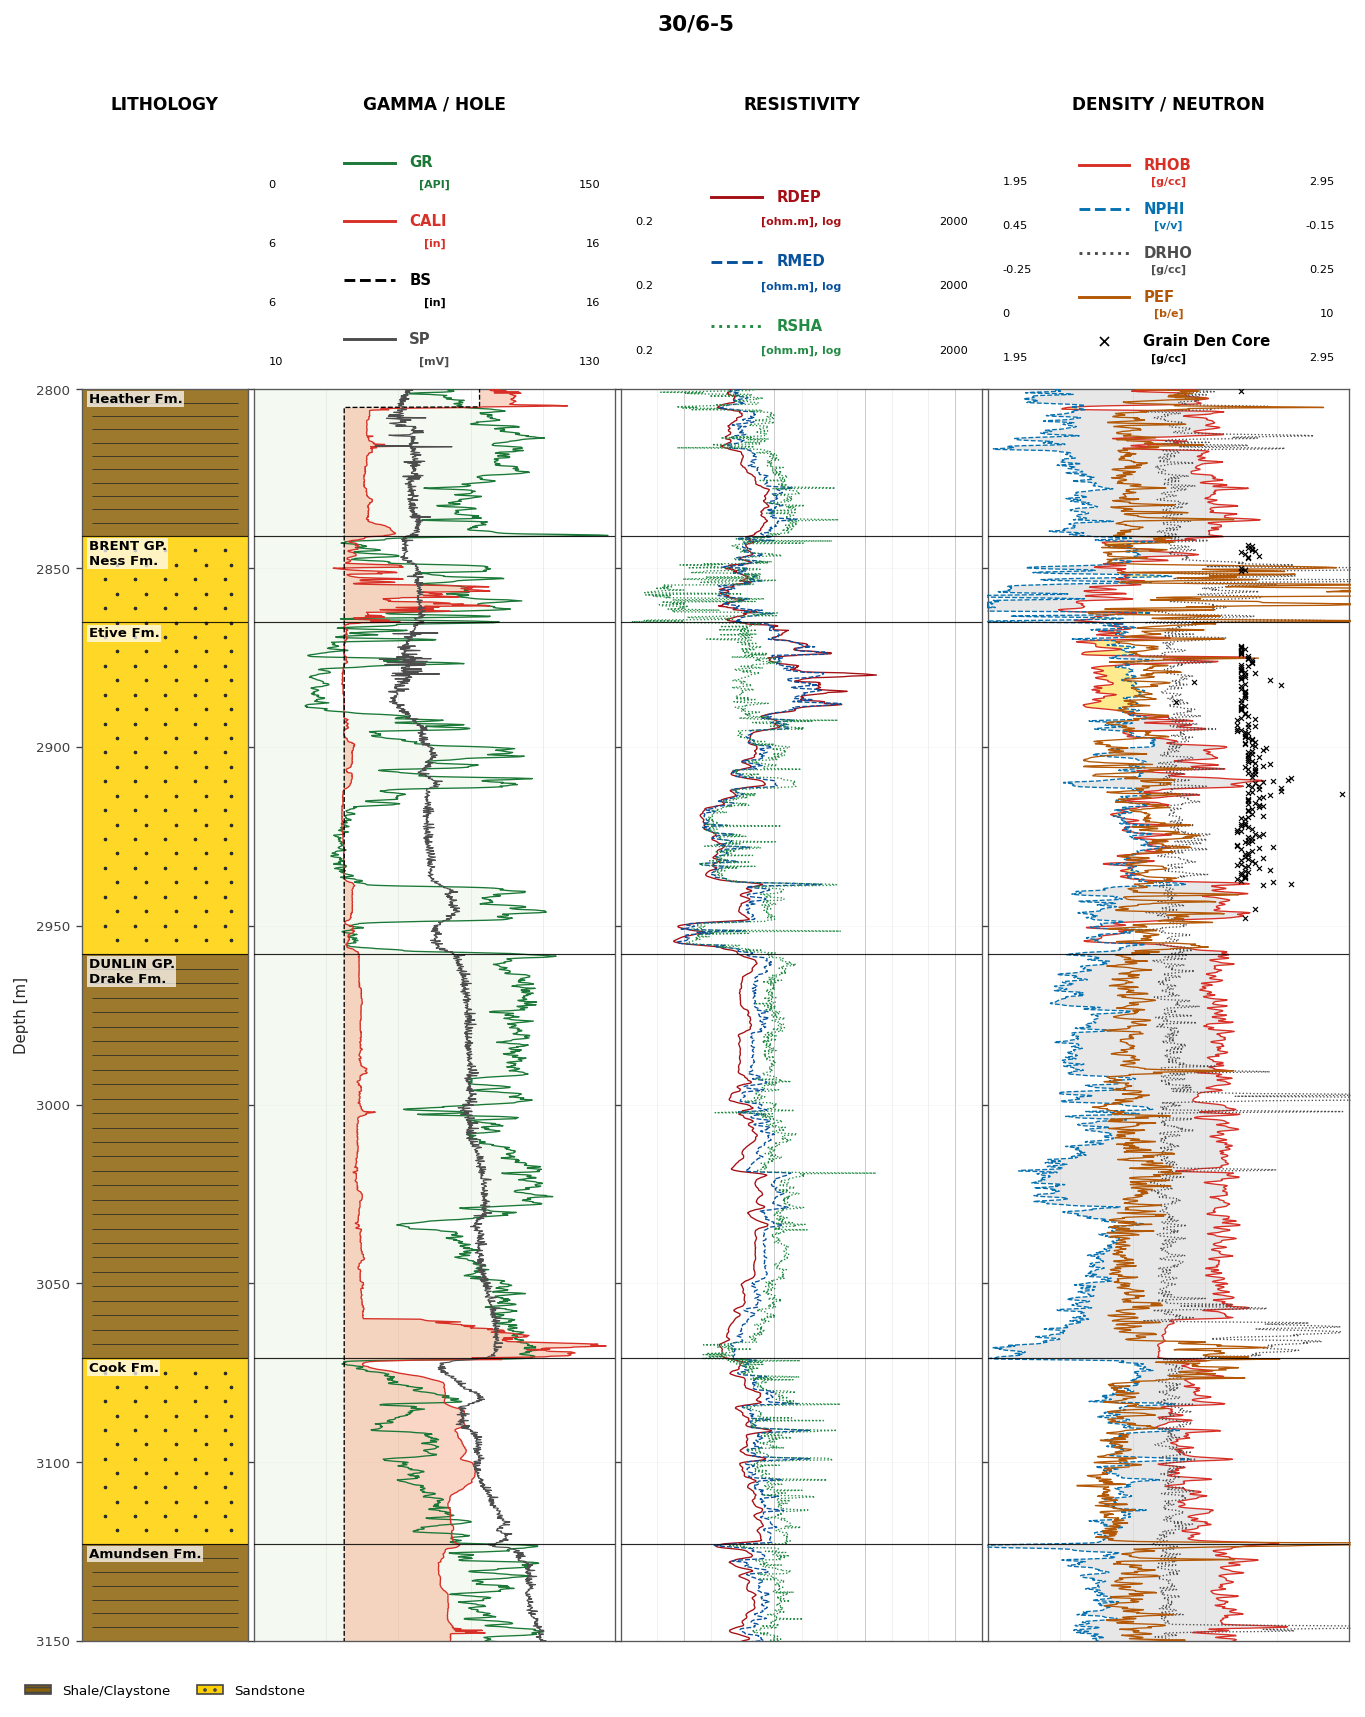

In [5]:
well = pp.read(pp.sample("30_6-5"), formations=pp.sample("formations_30_6-5"))
pp.plot(well, top=2800, bottom=3150, lithology=pp.sample("lithology_30_6-5"),
        tracks=["LITHOLOGY", "GAMMA / HOLE", "RESISTIVITY", "DENSITY / NEUTRON"]).show()

The coarse column calls the whole Brent Group sandstone and the Drake
Formation shale, while the logs show the shale breaks inside the Ness and the
lower Etive. A simplified column is a label for an interval, not a lithology log.
The horizontal lines and names are the formation tops.

The `UserWarning` lines under the plot are a genuine unit problem of this file:
the core saturation curves `SWC` and `SOC` are stored in percent although the
header labels them `frac`, so Petrophys divides them by 100. After reading the
note once, we silence **only that message**.

In [6]:
warnings.filterwarnings("ignore", message=r"(SWC|SOC): inferred percent core saturation")

## 3. Compute the interpretation curves to summarise

Per-interval statistics need computed curves (`PHIE`, `SW`, `VCL`, `PERM`,
`NET_PAY`, ...). We generate them with `pp.interpret`, using the same
documented environment as Lesson 10 for 30/6-5: Rw = 0.070 ohm.m **at 230 degF**
(`rw_meas_temp="230 degF"`), and explicitly pinned cutoffs so the report is
reproducible.

In [7]:
SETTINGS = dict(rw=0.070, rw_meas_temp="230 degF", vcl_cutoff=0.4, phie_cutoff=0.08, sw_cutoff=0.6)
result = pp.interpret(well, **SETTINGS)
result.status

'interpreted'

## 4. The per-formation report: `result.formation_summary`

`result.formation_summary(rank=...)` rolls the interpreted curves up per
formation, using the tops attached to the well (or a table you pass). The
bundled table mixes groups and the formations within them, so pass
`rank="formation"` (or `"group"`) to get one non-overlapping level. Each row
reports gross, net-rock, net-reservoir and net-pay thickness, net reservoir /
gross (`N/G (reservoir)`), net pay / gross (`Pay/Gross`), and averages.
`Avg PHIE`, `Avg Sw`, `Avg VCL` and `Avg Perm (mD)` are taken over the
**net-pay samples** only (NaN where a formation has no pay): porosity and clay
volume are thickness-weighted, Sw is pore-volume-weighted (each sample's Sw
counts with its porosity and thickness), and permeability is a geometric mean; `Avg GR`, `Avg RHOB` and the other log averages cover the
whole formation.

In [8]:
by_formation = result.formation_summary(rank="formation")
by_formation

,Formation,Top,Bottom,Gross (m),Net Rock (m),Net Reservoir (m),Net Pay (m),N/G (reservoir),Pay/Gross,Avg PHIE,Avg Sw,Avg VCL,Avg Perm (mD),Avg GR,Avg RHOB,Avg NPHI,Avg RDEP,Avg PHIT,HCPV,BVW,Samples,Pay Samples,Data Coverage %
0,Utsira Fm.,726.0,879.0,153.010,153.010,0.000,0.000,0.000,0.000,NaN,NaN,NaN,NaN,23.586,1.890,NaN,1.078,0.460,NaN,NaN,1004,0,100.000
1,Balder Fm.,1908.0,2023.0,115.062,81.686,53.950,0.000,0.469,0.000,NaN,NaN,NaN,NaN,49.052,2.197,0.422,1.087,0.342,NaN,NaN,755,0,100.000
2,Sele Fm.,2023.0,2123.0,99.974,86.868,11.430,0.000,0.114,0.000,NaN,NaN,NaN,NaN,50.667,2.196,0.433,0.843,0.347,NaN,NaN,656,0,100.000
3,Lista Fm.,2123.0,2203.0,80.010,79.096,46.634,0.305,0.583,0.004,0.384,0.597,0.266,2454.467,45.936,2.265,0.394,1.128,0.306,0.047,0.229,525,2,100.000
4,Draupne Fm.,2452.0,2593.0,140.970,0.000,0.000,0.000,0.000,0.000,NaN,NaN,NaN,NaN,132.166,2.347,0.415,2.253,0.284,NaN,NaN,925,0,100.000
5,Heather Fm.,2593.0,2841.0,247.955,14.478,5.334,0.305,0.022,0.001,0.296,0.562,0.057,2331.858,78.887,2.514,0.347,5.054,0.197,0.039,0.166,1627,2,100.000
6,Ness Fm.,2841.0,2865.0,24.079,11.125,7.620,2.286,0.316,0.095,0.212,0.535,0.054,317.415,75.012,2.316,0.310,4.191,0.253,0.226,0.114,158,15,100.000
7,Etive Fm.,2865.0,2958.0,92.964,65.379,58.369,22.860,0.628,0.246,0.223,0.247,0.057,607.154,56.143,2.407,0.225,9.417,0.187,3.838,0.055,610,150,100.000
8,Drake Fm.,2958.0,3071.0,113.081,0.000,0.000,0.000,0.000,0.000,NaN,NaN,NaN,NaN,102.970,2.574,0.297,4.925,0.155,NaN,NaN,742,0,100.000
9,Cook Fm.,3071.0,3123.0,51.968,10.821,0.762,0.000,0.015,0.000,NaN,NaN,NaN,NaN,68.140,2.509,0.229,5.484,0.152,NaN,NaN,341,0,100.000


### Why do shallow intervals show "pay"?

The table opens with formations far above the reservoir - the Utsira sand and
the Rogaland formations. Of the formations above the Brent Group, only the
Lista and Heather formations carry net pay: two samples each (0.3 m).

That does not mean the overburden is clean. Most of the Nordland and Hordaland
groups have no formations within them in this table, so their depth falls in no
`rank="formation"` row; the group view below shows it.

In [9]:
result.formation_summary(rank="group")

,Formation,Top,Bottom,Gross (m),Net Rock (m),Net Reservoir (m),Net Pay (m),N/G (reservoir),Pay/Gross,Avg PHIE,Avg Sw,Avg VCL,Avg Perm (mD),Avg GR,Avg RHOB,Avg NPHI,Avg RDEP,Avg PHIT,HCPV,BVW,Samples,Pay Samples,Data Coverage %
0,NORDLAND GP.,181.0,726.0,544.982,160.325,0.000,0.000,0.000,0.000e+00,NaN,NaN,NaN,NaN,58.417,1.901,NaN,5.409,0.452,NaN,NaN,3576,0,100.0
1,HORDALAND GP.,879.0,1908.0,1029.005,1017.575,536.448,22.708,0.521,2.207e-02,0.453,0.583,0.149,7758.567,39.165,1.958,0.522,0.969,0.463,4.297,0.264,6752,149,100.0
2,ROGALAND GP.,1908.0,2203.0,295.047,247.651,112.014,0.305,0.380,1.033e-03,0.384,0.597,0.266,2454.467,48.754,2.215,0.418,1.015,0.334,0.047,0.229,1936,2,100.0
3,SHETLAND GP.,2203.0,2408.0,204.978,106.680,27.583,0.152,0.135,7.438e-04,0.378,0.594,0.093,2442.753,57.746,2.391,0.368,1.412,0.259,0.023,0.225,1345,1,100.0
4,CROMER KNOLL GP.,2408.0,2452.0,44.043,36.424,15.545,0.000,0.353,0.000e+00,NaN,NaN,NaN,NaN,49.309,2.489,0.293,1.613,0.195,NaN,NaN,289,0,100.0
5,VIKING GP.,2452.0,2841.0,388.925,14.478,5.334,0.305,0.014,7.837e-04,0.296,0.562,0.057,2331.858,98.199,2.453,0.372,4.039,0.229,0.039,0.166,2552,2,100.0
6,BRENT GP.,2841.0,2958.0,117.043,76.504,65.989,25.146,0.564,2.148e-01,0.222,0.272,0.057,572.393,60.025,2.388,0.242,8.341,0.200,4.064,0.060,768,165,100.0
7,DUNLIN GP.,2958.0,3223.0,265.024,10.821,0.762,0.000,0.003,0.000e+00,NaN,NaN,NaN,NaN,92.734,2.573,0.271,5.356,0.145,NaN,NaN,1739,0,100.0


The Hordaland Group carries 22.7 m of flagged net pay. It is not a
reservoir: poorly compacted shallow sediments read very high apparent porosity
(its pay samples average a PHIE of 0.45), the clay indicators
disagree in their soft mudstones, and one Rw - corrected for temperature, at
constant salinity - serves the whole well although shallow formation water is
usually fresher, so samples can pass all three cutoffs. The flags describe log
values, not hydrocarbons: cutoffs do not know where the reservoir is. Silty or
sandy beds just above a reservoir can pass the cutoffs in the same way and need
review too. The group's pay-averaged permeability, 7,759 mD, is a second warning
sign: most of its pay samples sit at the 10,000 mD ceiling of the permeability
transform, an artefact of the transform at high porosity, not a rock property.

That is why a whole-well total is not a reservoir number. `result.summary()`
gives the whole well, and `result.summary(top=..., bottom=...)` a window - here
the Brent Group:

In [10]:
pd.DataFrame({"Whole well": result.summary()["net_thickness"],
              "Brent Group, 2841-2958 m": result.summary(top=2841, bottom=2958)["net_thickness"]})

,Whole well,"Brent Group, 2841-2958 m"
depth_unit,m,m
net_rock,2013.66,76.5
net_res,810.61,65.99
net_pay,49.38,25.15


Of the 49.4 m of net pay flagged in the whole well, 24.2 m lies outside the
Brent Group (25.1 m), most of it the Hordaland flags.

### Focus on the reservoir formations

In 30/6-5 the reservoir is the Brent Group (Ness and Etive formations), with
thinner sands deeper in the Dunlin Group (Cook Fm.) and in the Statfjord Group
(`Statfjord Fm.` in the bundled tops, the picks' label). Report those rows;
every other row needs its own geological justification (pressures, shows,
tests) before its flags count.

In [11]:
by_formation[by_formation["Formation"].isin(["Ness Fm.", "Etive Fm.", "Cook Fm.", "Statfjord Fm."])]

,Formation,Top,Bottom,Gross (m),Net Rock (m),Net Reservoir (m),Net Pay (m),N/G (reservoir),Pay/Gross,Avg PHIE,Avg Sw,Avg VCL,Avg Perm (mD),Avg GR,Avg RHOB,Avg NPHI,Avg RDEP,Avg PHIT,HCPV,BVW,Samples,Pay Samples,Data Coverage %
6,Ness Fm.,2841.0,2865.0,24.079,11.125,7.620,2.286,0.316,0.095,0.212,0.535,0.054,317.415,75.012,2.316,0.310,4.191,0.253,0.226,0.114,158,15,100.000
7,Etive Fm.,2865.0,2958.0,92.964,65.379,58.369,22.860,0.628,0.246,0.223,0.247,0.057,607.154,56.143,2.407,0.225,9.417,0.187,3.838,0.055,610,150,100.000
9,Cook Fm.,3071.0,3123.0,51.968,10.821,0.762,0.000,0.015,0.000,NaN,NaN,NaN,NaN,68.140,2.509,0.229,5.484,0.152,NaN,NaN,341,0,100.000
11,Statfjord Fm.,3223.0,3556.0,332.994,185.775,46.939,0.762,0.141,0.002,0.305,0.392,0.034,1187.082,84.139,2.522,0.157,6.505,0.117,0.141,0.120,2185,5,99.817


The Brent Group carries 25.1 m of net pay: 22.9 m in the Etive (a quarter of
its gross thickness) and 2.3 m in the shalier Ness. The Statfjord flags 0.8 m
(five samples) in 333 m - a review candidate, not a completion recommendation.
The Cook sand has 0.8 m of net reservoir and no pay; the plot in section 7
shows why.

## 5. Any depth window: `result.zone_summary`

The formation report is the front door. When you need ad-hoc intervals - a
reservoir unit that the tops split, a cored interval, a test interval - pass
them to `result.zone_summary` as a list of `{zone, top, bottom}` rows (or a
CSV/Excel table with those columns). It returns the same columns as the
formation report. (`petrophys.evaluation.intervals.IntervalAnalyzer` adds the
dominant lithology of each interval, if you need it.)

In [12]:
zones = [{"zone": "Brent Group (Ness+Etive)", "top": 2841, "bottom": 2958},
         {"zone": "Cook Fm.", "top": 3071, "bottom": 3123},
         {"zone": "Statfjord", "top": 3223, "bottom": 3556}]
result.zone_summary(zones)

,Zone,Top,Bottom,Gross (m),Net Rock (m),Net Reservoir (m),Net Pay (m),N/G (reservoir),Pay/Gross,Avg PHIE,Avg Sw,Avg VCL,Avg Perm (mD),Avg GR,Avg RHOB,Avg NPHI,Avg RDEP,Avg PHIT,HCPV,BVW,Samples,Pay Samples,Data Coverage %
0,Brent Group (Ness+Etive),2841.0,2958.0,117.043,76.504,65.989,25.146,0.564,0.215,0.222,0.272,0.057,572.393,60.025,2.388,0.242,8.341,0.200,4.064,0.06,768,165,100.000
1,Cook Fm.,3071.0,3123.0,51.968,10.821,0.762,0.000,0.015,0.000,NaN,NaN,NaN,NaN,68.140,2.509,0.229,5.484,0.152,NaN,NaN,341,0,100.000
2,Statfjord,3223.0,3556.0,332.994,185.775,46.939,0.762,0.141,0.002,0.305,0.392,0.034,1187.082,84.139,2.522,0.157,6.505,0.117,0.141,0.12,2185,5,99.817


The Brent row equals the `BRENT GP.` row of section 4, and the Cook and
Statfjord rows equal their formation rows: the same samples give the same
numbers, whichever way the interval is named.

`HCPV` here is a hydrocarbon thickness index: the sum of PHIE x (1 - Sw) x
thickness over the pay samples, in metres. With the averages weighted as in
section 4 it equals `Avg PHIE` x (1 - `Avg Sw`) x `Net Pay (m)` of the same row:
for the Brent Group, 0.222 x (1 - 0.272) x 25.146 = 4.06 m. It is a column of hydrocarbon per
unit area, not an OOIP volume.

### Top-only picks need a final boundary

Tops given without bottoms are read as picks: each formation runs to the next
top, and the last one to the bottom of the log. Picks for the Ness, the Etive
and the Drake give the Drake row everything below 2958 m - the Dunlin Group and
the Statfjord sand as well:

In [13]:
result.formation_summary({"Ness Fm.": 2841, "Etive Fm.": 2865, "Drake Fm.": 2958})

,Formation,Top,Bottom,Gross (m),Net Rock (m),Net Reservoir (m),Net Pay (m),N/G (reservoir),Pay/Gross,Avg PHIE,Avg Sw,Avg VCL,Avg Perm (mD),Avg GR,Avg RHOB,Avg NPHI,Avg RDEP,Avg PHIT,HCPV,BVW,Samples,Pay Samples,Data Coverage %
0,Ness Fm.,2841.0,2865.00,24.079,11.125,7.620,2.286,0.316,0.095,0.212,0.535,0.054,317.415,75.012,2.316,0.310,4.191,0.253,0.226,0.114,158,15,100.000
1,Etive Fm.,2865.0,2958.00,92.964,65.379,58.369,22.860,0.628,0.246,0.223,0.247,0.057,607.154,56.143,2.407,0.225,9.417,0.187,3.838,0.055,610,150,100.000
2,Drake Fm.,2958.0,3556.08,598.170,196.596,47.701,0.762,0.080,0.001,0.305,0.392,0.034,1187.082,87.973,2.545,0.207,5.995,0.130,0.141,0.120,3925,5,99.873


The Drake row runs to 3556.08 m, the bottom of the log: 598 m gross instead of
113 m, and it takes over the Statfjord's 0.8 m of pay. Give the last pick its bottom (a `bottom_depth` column), or add the
top of the unit below it, before you report that row.

### Nested groups and totals

Tops that mix groups and formations overlap, and `formation_summary` without
`rank` defaults to the formation level for such a table. Never add rows of
different ranks: the `BRENT GP.` row of section 4 already is the Ness plus the
Etive row. Each sample counts with its depth cell - from halfway to the sample
above to halfway to the sample below, one step on a regular grid, with data
gaps not counted - so thickness is not simply bottom minus top. Formation
summary boundaries are [top, bottom), with the well's final sample included.

## 6. From file to report in one line

`pp.interpret` reads a file itself and takes the tops as `formations=`, so the
whole route from a LAS file to the per-formation report is one line.
(`petrophys.evaluation.summaries.run_formation_analysis` does the same and also
returns union totals over the rows.)

In [14]:
pp.interpret(pp.sample("30_6-5"), formations=pp.sample("formations_30_6-5"),
             **SETTINGS).formation_summary(rank="group")[["Formation", "Gross (m)", "Net Pay (m)"]]

,Formation,Gross (m),Net Pay (m)
0,NORDLAND GP.,544.982,0.000
1,HORDALAND GP.,1029.005,22.708
2,ROGALAND GP.,295.047,0.305
3,SHETLAND GP.,204.978,0.152
4,CROMER KNOLL GP.,44.043,0.000
5,VIKING GP.,388.925,0.305
6,BRENT GP.,117.043,25.146
7,DUNLIN GP.,265.024,0.000


The rows match the group table of section 4: the same file, tops and settings
give the same report.

## 7. Depth plot with formation shading

Finally, the visual. `pp.plot` draws the attached formation tops as top
markers - a thin line across every track, with the name in the lithology track.
It does not shade intervals. `add_zone_shading` paints coloured spans onto one
track of the figure: it takes a list of `{top, bottom, name, color}` rows. We
shade the Brent Group and the Cook Formation on the gamma-ray track of the
interpretation plot, the second track of the figure (`viewer.axes[1]`).

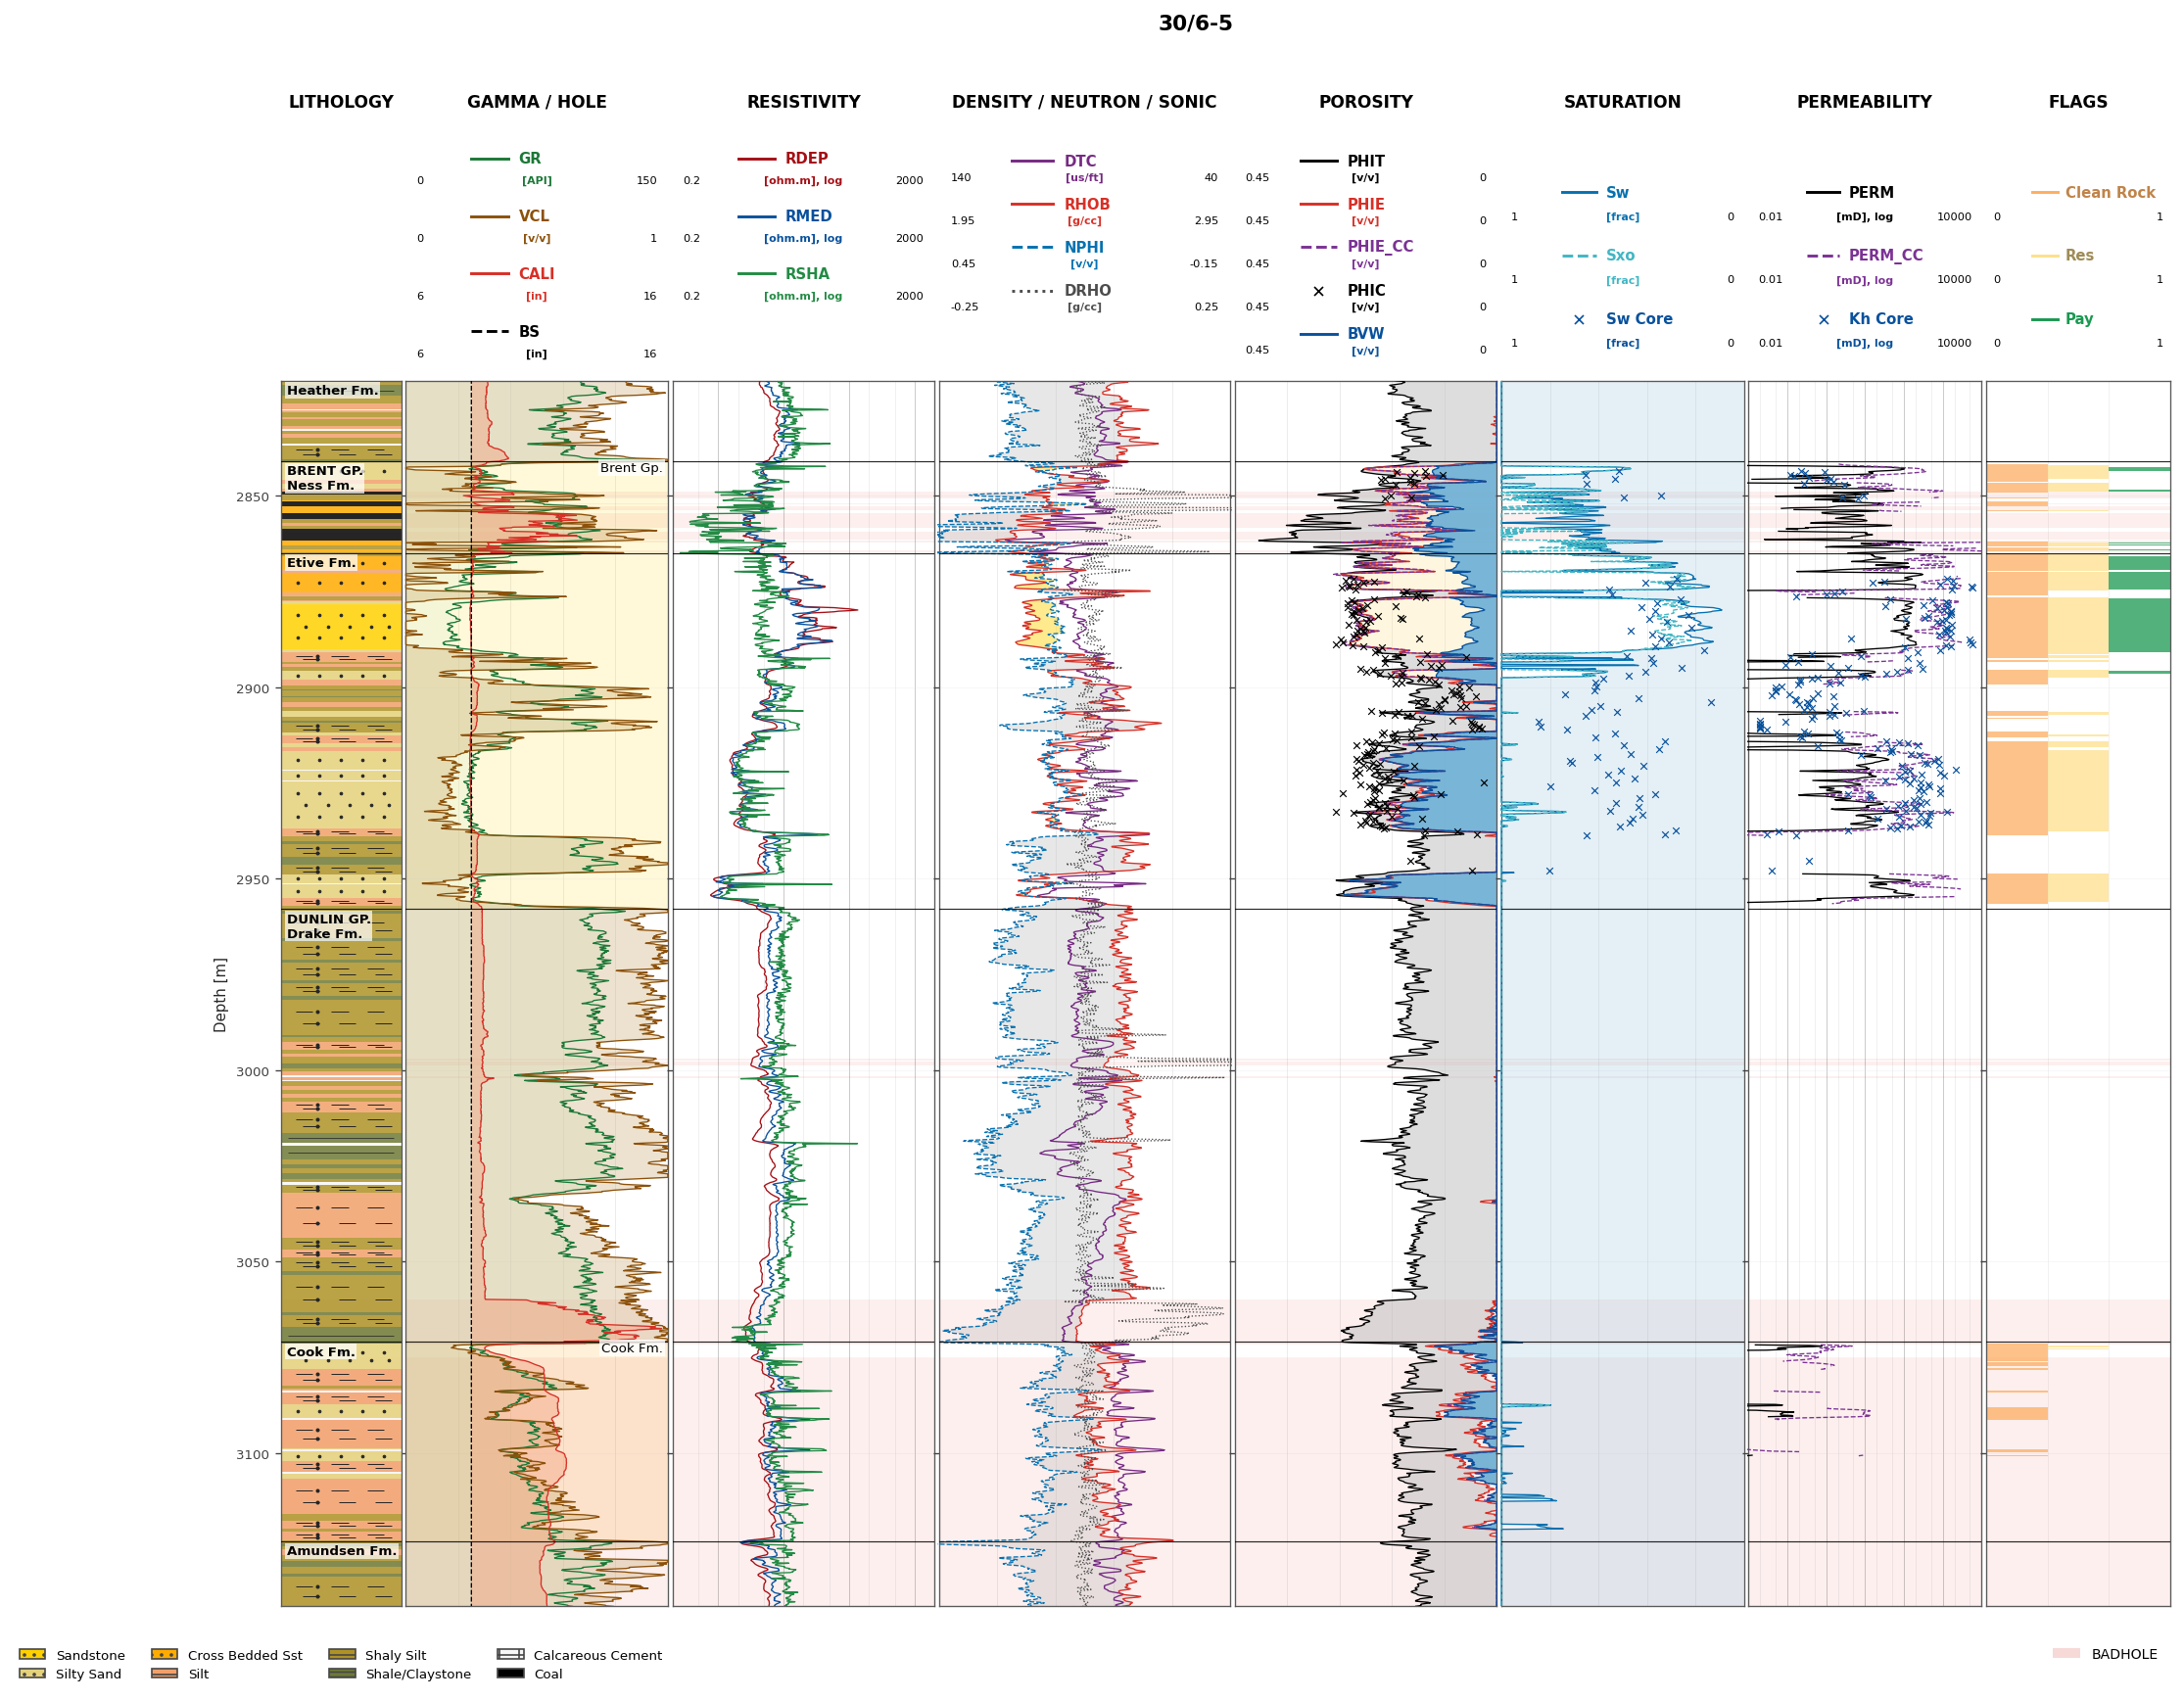

In [15]:
viewer = pp.plot(result, template="petrophysics", top=2820, bottom=3140)
add_zone_shading(viewer.axes[1], [{"top": 2841, "bottom": 2958, "name": "Brent Gp.", "color": "gold"},
                                  {"top": 3071, "bottom": 3123, "name": "Cook Fm.", "color": "orange"}])
viewer.show()

The gold span is the Brent Group, the orange one the Cook Formation. The Cook
sits in washed-out hole: the caliper reads well over the bit size, and the pink
`BAD_HOLE` band covers all of the formation but its top 3 m. Density, neutron, PHIE and Sw are
unreliable there, so the net-pay step leaves those samples out - that, not the
rock, is why the Cook row has no net pay. A formation report is only as good as
the hole it was logged in. Labels of crowded tops can be suppressed in a short window;
`viewer.diagnostics["suppressed_formation_labels"]` lists them, so an
unlabelled boundary is not mistaken for one absent from the input.

## Pitfalls and parameter choices

- Net-pay cutoffs flag log values, not hydrocarbons. Shallow, poorly compacted
  sediments can pass them; report reservoir formations (or a reservoir depth
  window), not whole-well totals.
- Rows at one rank cover only depth that has a top at that rank. Depth with a
  group top but no formations within it (the Hordaland Group here) is in no
  `rank="formation"` row; compare row totals with `result.summary()`.
- Tops that mix groups and formations overlap. Pick one level with `rank=`;
  never add overlapping rows by hand.
- Top-only picks run to the next top, and the last one to the bottom of the
  log; give the last one a bottom.
- Supply or verify depth units, reference and datum. Compatible length units
  can be converted; MD/TVD and datum changes need real transformations.
- A simplified lithology column labels intervals; it does not replace the
  lithology log inside them.
- Pay-averaged properties and the HCPV thickness index are not whole-interval
  statistics or volumetric OOIP.

## Recap

- `pp.read_formations` reads tops with their rank and parent;
  `pp.read(..., formations=...)` attaches them to the well.
- `result.formation_summary(rank="formation")` is the front-door
  per-formation report: thicknesses, NTG and pay-averaged properties;
  `rank="group"` gives the group level.
- Shallow overburden can pass net-pay cutoffs; focus the report on the
  reservoir units (here Ness, Etive, Cook and the Statfjord Group).
- `result.zone_summary(zones)` reports any list of depth windows, and
  `result.summary(top=..., bottom=...)` one window.
- `pp.plot` draws formation tops; `add_zone_shading` paints named spans on a
  track.

## Try it yourself

> **Exercise 1.** Read `lithology_30_6-5.csv` with pandas, rename its
> `lithology` column to `zone`, and pass it to `result.zone_summary`. Compare
> net pay bucketed by *lithology* against the formation buckets.
>
> **Exercise 2.** Find the `Draupne Fm.` row (a source-rock shale) in
> `by_formation`. Does it carry flagged pay, and what in its logs could make
> samples pass the cutoffs?
>
> **Exercise 3.** Re-run `pp.interpret` with `sw_cutoff=0.5` and compare
> `formation_summary(rank="formation")` against the base run - which reservoir
> formations lose the most net pay?

## What's next

Continue with **12 - Core Calibration and the Digital Core** before treating
any interval summary as decision-ready. For file mapping, templates and error
handling, revisit [Your own data](../../docs/own_data.md). Formation and lithology
inputs remain optional for the underlying interpretation workflow.